In [2]:
import torch
import torch.nn as nn
import torch.nn.functional as F

from rdkit import Chem
from torch_geometric.nn import GINEConv, global_mean_pool

device = torch.device(
    "cuda" if torch.cuda.is_available() else "cpu"
)

# Read checkpoint metadata
ckpt = torch.load(
    "checkpoints/finetuning/Random_FineTuned.pt",
    map_location="cpu",
    weights_only=True
)

ELEMENTS = list(ckpt["elements"])
VOCAB_SIZE = ckpt["vocab_size"]

ATOM_TO_ID = {
    z: i + 1 for i, z in enumerate(ELEMENTS)
}

UNK_ID = len(ELEMENTS) + 1
MASK_ID = len(ELEMENTS) + 2

BOND_TYPES = [
    Chem.BondType.SINGLE,
    Chem.BondType.DOUBLE,
    Chem.BondType.TRIPLE,
    Chem.BondType.AROMATIC
]


class MolecularGINEEncoder(nn.Module):

    def __init__(
        self,
        hidden=64,
        num_layers=3,
        dropout=0.1
    ):
        super().__init__()

        self.atom_embedding = nn.Embedding(
            VOCAB_SIZE, hidden
        )

        self.convs = nn.ModuleList()
        self.norms = nn.ModuleList()

        self.dropout = dropout

        for _ in range(num_layers):

            mlp = nn.Sequential(
                nn.Linear(hidden, hidden),
                nn.ReLU(),
                nn.Linear(hidden, hidden)
            )

            self.convs.append(
                GINEConv(mlp, edge_dim=4)
            )

            self.norms.append(nn.LayerNorm(hidden))

    def forward(self, x, edge_index, edge_attr):

        h = self.atom_embedding(x)

        for conv, norm in zip(self.convs, self.norms):

            update = conv(
                h, edge_index, edge_attr
            )

            h = F.relu(norm(h + update))

            h = F.dropout(
                h,
                p=self.dropout,
                training=self.training
            )

        return h


class PPI_GINE(nn.Module):

    def __init__(self, dropout=0.2):
        super().__init__()

        self.encoder = MolecularGINEEncoder()

        self.regressor = nn.Sequential(
            nn.Linear(64, 32),
            nn.ReLU(),
            nn.Dropout(dropout),
            nn.Linear(32, 1)
        )

    def forward(self, batch):

        h = self.encoder(
            batch.x,
            batch.edge_index,
            batch.edge_attr
        )

        molecular_embedding = global_mean_pool(
            h, batch.batch
        )

        return self.regressor(
            molecular_embedding
        ).view(-1)

  warnings.warn(


In [3]:
model = PPI_GINE().to(device)

model.load_state_dict(
    ckpt["model_state_dict"],
    strict=True
)

model.eval()

y_mean = ckpt["y_mean"]
y_std = ckpt["y_std"]

print("Fine-tuned model restored successfully!")
print("Device:", device)
print("Best fine-tuning epoch:", ckpt["best_epoch"])
print("Training target mean:", y_mean)
print("Training target standard deviation:", y_std)

Fine-tuned model restored successfully!
Device: cuda
Best fine-tuning epoch: 188
Training target mean: 5.512244408437319
Training target standard deviation: 0.7967683258188706


In [4]:

from torch_geometric.data import Data

def smiles_to_graph(smiles):
    mol = Chem.MolFromSmiles(smiles)

    if mol is None or mol.GetNumAtoms() == 0:
        return None

    atom_ids = [
        ATOM_TO_ID.get(atom.GetAtomicNum(), UNK_ID)
        for atom in mol.GetAtoms()
    ]

    edges = []
    edge_features = []

    for bond in mol.GetBonds():
        i = bond.GetBeginAtomIdx()
        j = bond.GetEndAtomIdx()

        feature = [
            float(bond.GetBondType() == b)
            for b in BOND_TYPES
        ]

        for source, target in [(i, j), (j, i)]:
            edges.append([source, target])
            edge_features.append(feature)

    if edges:
        edge_index = torch.tensor(
            edges, dtype=torch.long
        ).T.contiguous()
        edge_attr = torch.tensor(
            edge_features, dtype=torch.float32
        )
    else:
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr = torch.empty((0, 4), dtype=torch.float32)

    return Data(
        x=torch.tensor(atom_ids, dtype=torch.long),
        edge_index=edge_index,
        edge_attr=edge_attr
    )


In [5]:

import pandas as pd
import numpy as np

from torch_geometric.loader import DataLoader

candidates = pd.read_csv(
    "data/processed/chembl37_pretrain_all.csv"
)

valid_graphs = []
valid_indices = []

for i, smiles in enumerate(candidates["canonical_smiles"]):
    graph = smiles_to_graph(smiles)

    if graph is not None:
        valid_graphs.append(graph)
        valid_indices.append(i)

loader = DataLoader(
    valid_graphs,
    batch_size=256,
    shuffle=False
)

predictions = []

model.eval()

with torch.inference_mode():
    for batch in loader:
        batch = batch.to(device)

        output = model(batch)
        predicted_pIC50 = output * y_std + y_mean

        predictions.extend(
            predicted_pIC50.cpu().numpy()
        )

screened = candidates.iloc[valid_indices].copy()
screened["predicted_pIC50"] = predictions

screened = screened.sort_values(
    "predicted_pIC50",
    ascending=False
)

print("Molecules screened:", len(screened))

display(
    screened[
        ["chembl_id", "canonical_smiles", "predicted_pIC50"]
    ].head(20)
)

screened.to_csv(
    "PPI_ChEMBL_screening_predictions.csv",
    index=False
)


Molecules screened: 100000


,chembl_id,canonical_smiles,predicted_pIC50
23918,CHEMBL2288325,C[N+](C)(C)C,8.250437
30894,CHEMBL553354,CN1CCN(CC#N)CC1,7.908523
43090,CHEMBL3306397,C[N+](C)(C)Cc1ccc(C[N+](C)(C)C)c(I)c1,7.847429
96864,CHEMBL118050,C(CCNCCCN1CC1)CNCCCN1CC1,7.825500
82527,CHEMBL118765,CN(C)CCCCCCN(C)C,7.800670
72448,CHEMBL538588,CN(C)Cc1ccc(CN(C)C)cc1,7.786786
61239,CHEMBL9324,CC[N+](CC)(CC)CC,7.768301
43744,CHEMBL4566983,CCN1CCN(C2CCNCC2)CC1,7.768271
28049,CHEMBL1413894,CCN1CCN(CC2COc3ccccc3O2)CC1,7.766634
98392,CHEMBL3391935,C[N+]1(CCCl)CC[N+](C)(CCCl)CC1,7.730961


In [6]:
"""Postprocess the ChEMBL virtual-screening CSV.

Inputs (from earlier notebooks):
    PPI_ChEMBL_screening_predictions.csv
    PPI_molecule_summary_248.csv
Outputs:
    PPI_top3000_diagnostics.csv
    PPI_exploratory_filtered_from_top3000.csv

Run: python 05_PPI_screening_diagnostics.py
"""
from pathlib import Path
import numpy as np
import pandas as pd
from rdkit import Chem, DataStructs
from rdkit.Chem import Descriptors, Crippen, rdMolDescriptors, rdFingerprintGenerator

SCREENING_CSV = Path('PPI_ChEMBL_screening_predictions.csv')
PPI_CSV = Path('PPI_molecule_summary_248.csv')
TOP_N = 3000

screened = pd.read_csv(SCREENING_CSV)
ppi = pd.read_csv(PPI_CSV)

required_screening = {'chembl_id','canonical_smiles','predicted_pIC50'}
required_ppi = {'molecule_chembl_id','canonical_smiles'}
assert required_screening.issubset(screened.columns), 'Missing screening columns'
assert required_ppi.issubset(ppi.columns), 'Missing PPI reference columns'

screened['predicted_pIC50'] = pd.to_numeric(screened['predicted_pIC50'], errors='coerce')
screened = screened.dropna(subset=['predicted_pIC50', 'canonical_smiles'])
screened = screened.sort_values('predicted_pIC50', ascending=False, kind='stable')
top = screened.head(TOP_N).copy().reset_index(drop=True)

fingerprinter = rdFingerprintGenerator.GetMorganGenerator(radius=2, fpSize=2048)
reference_ids = []
reference_fps = []
for row in ppi.itertuples(index=False):
    mol = Chem.MolFromSmiles(row.canonical_smiles)
    if mol is not None:
        reference_ids.append(row.molecule_chembl_id)
        reference_fps.append(fingerprinter.GetFingerprint(mol))
if not reference_fps:
    raise ValueError('No valid PPI reference molecules')

rows = []
for row in top.itertuples(index=False):
    mol = Chem.MolFromSmiles(row.canonical_smiles)
    if mol is None:
        rows.append((np.nan, np.nan, np.nan, np.nan, np.nan, None))
        continue
    fp = fingerprinter.GetFingerprint(mol)
    scores = DataStructs.BulkTanimotoSimilarity(fp, reference_fps)
    nearest_idx = int(np.argmax(scores))
    rows.append((
        Descriptors.MolWt(mol),
        Crippen.MolLogP(mol),
        rdMolDescriptors.CalcTPSA(mol),
        Chem.GetFormalCharge(mol),
        scores[nearest_idx],
        reference_ids[nearest_idx]
    ))

extra_cols = ['MW', 'LogP', 'TPSA', 'formal_charge',
              'max_tanimoto_to_PPI', 'nearest_PPI_id']
for col, values in zip(extra_cols, zip(*rows)):
    top[col] = list(values)

out_all = Path('PPI_top3000_diagnostics.csv')
top.to_csv(out_all, index=False)

mask = (
    top['formal_charge'].eq(0)
    & top['MW'].between(200, 550)
    & top['LogP'].between(-1, 5)
    & top['TPSA'].le(140)
    & top['max_tanimoto_to_PPI'].ge(0.5)
)
filtered = top.loc[mask].copy()
out_filtered = Path('PPI_exploratory_filtered_from_top3000.csv')
filtered.to_csv(out_filtered, index=False)

print('Total screening rows:', len(screened))
print('Top rows analyzed:', len(top))
print('PPI reference fingerprints:', len(reference_fps))
print('Rows passing exploratory filters:', len(filtered))
if not filtered.empty:
    print(filtered[['chembl_id', 'predicted_pIC50', 'max_tanimoto_to_PPI']].to_string(index=False))


Total screening rows: 100000
Top rows analyzed: 3000
PPI reference fingerprints: 248
Rows passing exploratory filters: 3
    chembl_id  predicted_pIC50  max_tanimoto_to_PPI
 CHEMBL168635         7.371090             0.543478
 CHEMBL368577         7.003401             0.739130
CHEMBL1624537         6.841448             0.500000


In [ ]:
#%run 05_PPI_screening_diagnostics.py

In [7]:
%run 06_PPI_Applicability_Domain.py


Reproduced held-out metrics:
   split     model  n_test   MAE  RMSE    R2
  Random   Scratch      50 0.484 0.634 0.393
  Random    Frozen      50 0.515 0.645 0.371
  Random FineTuned      50 0.407 0.523 0.586
Scaffold   Scratch      38 0.821 0.955 0.021
Scaffold    Frozen      38 0.779 0.919 0.094
Scaffold FineTuned      38 0.716 0.856 0.213

Top-3000 diagnostic summary:
Charged candidates: 154
Similarity <0.3: 2842
Passing exploratory filters: 2

Important: similarity is not calibrated uncertainty. No new experimental IC50 values were obtained.


In [8]:
%run 07_PPI_omeprazole_scaffold_search.py

 screened_molecules  candidate_matches  core_retaining_hits  similarity_only_hits  similarity_threshold
             100000                  0                    0                     0                  0.45

Top 15 chemistry-prioritized hits:
Empty DataFrame
Columns: [chembl_id, predicted_pIC50, similarity_to_omeprazole, retains_sulfoxide_benzimidazole, formal_charge]
Index: []

Saved to: analysis/omeprazole_series


In [9]:
%run 08_PPI_corrected_scaffold_search.py

Scanned: 100000 | invalid SMILES: 0
Matches: 33 | sulfoxide–benzimidazole core: 7
Unlabeled candidates: 33
    chembl_id                                                         canonical_smiles  retains_sulfoxide_benzimidazole  similarity_to_omeprazole  known_labeled_PPI  predicted_pIC50_100k_screen
 CHEMBL440676                    COc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(N4CCCC4)c3Cl)nc2c1                             True                  0.640625              False                     5.623321
CHEMBL1796637    COc1c(C)cnc(C[S+]([O-])c2nc3cc(Oc4ccccc4)c(NC(=O)c4ccco4)cc3[nH]2)c1C                             True                  0.531646              False                     5.426835
  CHEMBL61451                     COc1ccc2[nH]c([S+]([O-])Cc3cc(N4CCOCC4)c(F)cn3)nc2c1                             True                  0.500000              False                     5.346081
CHEMBL2297299              COc1ccc2[nH]c([S+]([O-])Cc3nc(OC)c4c(-c5ccccc5)csc4n3)nc2c1                             Tr

Total molecules: 802
Columns: ['chembl_id', 'canonical_smiles', 'retains_sulfoxide_benzimidazole', 'similarity_to_omeprazole', 'known_labeled_PPI', 'predicted_pIC50_100k_screen']
SMILES file generated successfully!


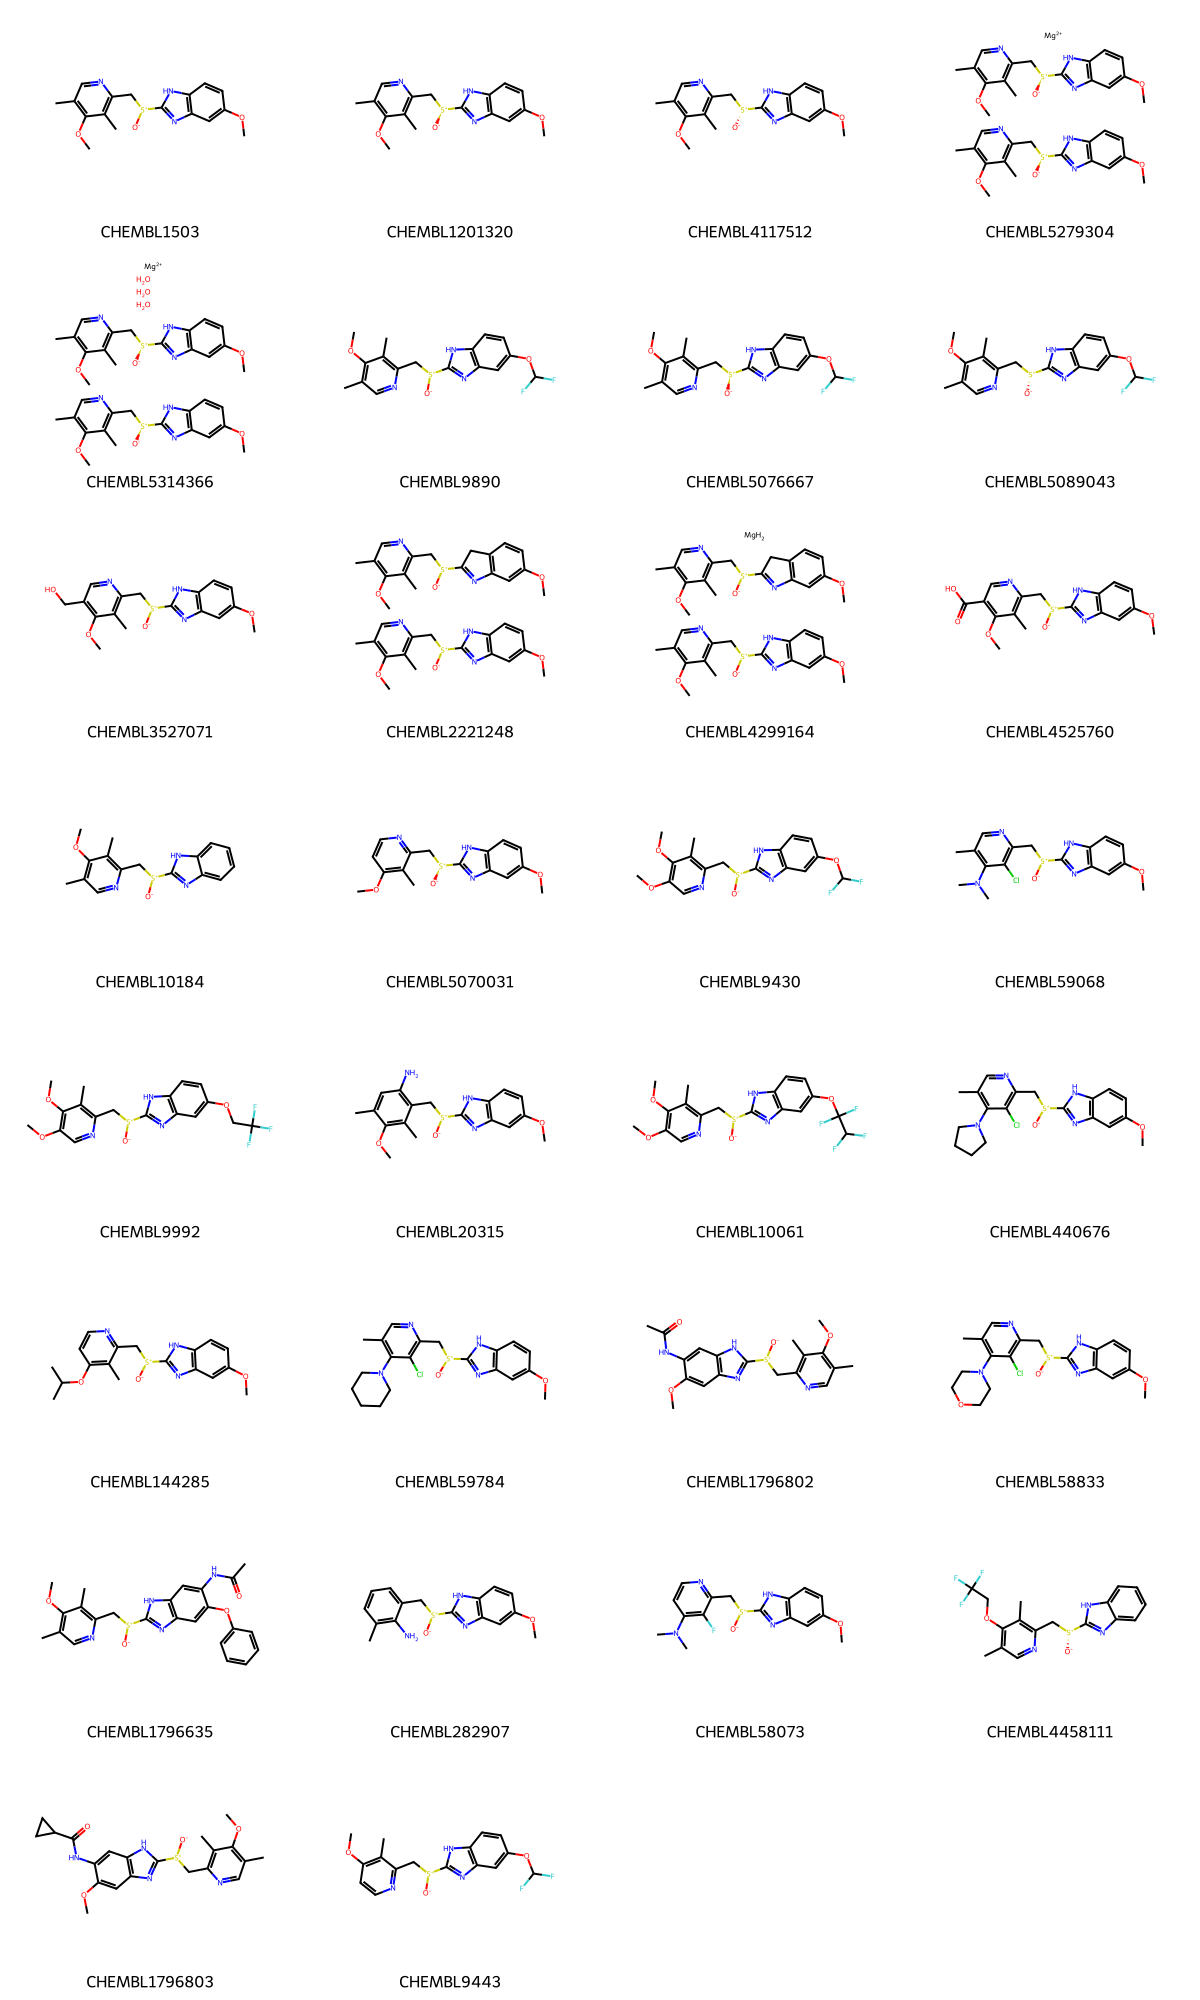

In [12]:
import pandas as pd

df = pd.read_csv(
    "analysis/omeprazole_series/full_chembl37_corrected_matches.csv"
)

print("Total molecules:", len(df))
print("Columns:", df.columns.tolist())

# Save one SMILES per line
df["canonical_smiles"].dropna().to_csv(
    "analysis/omeprazole_series/omeprazole_analog_smiles.txt",
    index=False,
    header=False
)

print("SMILES file generated successfully!")

# %%
from rdkit import Chem
from rdkit.Chem import Draw
from IPython.display import display

mols = []
legends = []

for row in df.itertuples():
    mol = Chem.MolFromSmiles(row.canonical_smiles)

    if mol is not None:
        mols.append(mol)
        legends.append(str(row.chembl_id))

# Display the first 30 molecules
img = Draw.MolsToGridImage(
    mols[:30],
    legends=legends[:30],
    molsPerRow=4,
    subImgSize=(300, 250)
)

display(img)

In [14]:
from pathlib import Path
from io import BytesIO
from PIL import Image
from rdkit.Chem import Draw

output_dir = Path("analysis/omeprazole_series")
output_dir.mkdir(parents=True, exist_ok=True)

batch_size = 40
pages = []

for start in range(0, len(mols), batch_size):
    end = min(start + batch_size, len(mols))

    img = Draw.MolsToGridImage(
        mols[start:end],
        legends=legends[start:end],
        molsPerRow=4,
        subImgSize=(350, 250),
        useSVG=False,
        returnPNG=True
    )

    # Convert PNG bytes / IPython image into a PIL image
    if isinstance(img, Image.Image):
        page = img.convert("RGB")
    else:
        png_data = img.data if hasattr(img, "data") else img
        page = Image.open(BytesIO(png_data)).convert("RGB")

    pages.append(page)

pdf_path = output_dir / "All_Omeprazole_Analogues.pdf"

if pages:
    pages[0].save(
        pdf_path,
        save_all=True,
        append_images=pages[1:],
        resolution=150
    )

    print("Total pages:", len(pages))
    print("Total molecules:", len(mols))
else:
    print("No valid molecules to export.")

Total pages: 21
Total molecules: 802


In [1]:
%run 10_prepare_full_chembl.py

usage: 10_prepare_full_chembl.py [-h] --input INPUT --ppi PPI [--out OUT]
                                 [--max-rows MAX_ROWS]
10_prepare_full_chembl.py: error: the following arguments are required: --input, --ppi


SystemExit: 2

In [2]:
import pandas as pd
from pathlib import Path

data_dir = Path("data/full_chembl37")

for split in ["train", "val", "test"]:
    path = data_dir / f"chembl37_{split}.csv"

    df = pd.read_csv(path, nrows=5)

    print(f"\n{split.upper()}")
    print("Columns:", df.columns.tolist())
    display(df.head())


TRAIN
Columns: ['chembl_id', 'canonical_smiles']


,chembl_id,canonical_smiles
0,CHEMBL405398,Brc1cccc(Nc2ncnc3ccncc23)c1NCCN1CCOCC1
1,CHEMBL503634,COc1c(O)cc(O)c(C(=N)Cc2ccc(O)cc2)c1O
2,CHEMBL503643,CCOC(=O)c1cc2cc(C(=O)O)ccc2[nH]1
3,CHEMBL503865,CC(=O)O[C@@H]1[C@@H](OC(C)=O)/C(C)=C\[C@@H]2OC...
4,CHEMBL504077,COc1ccc2c(c1OC)C(CC1(C)C=Cc3c(c4cccc(OC)c4n(C)...



VAL
Columns: ['chembl_id', 'canonical_smiles']


,chembl_id,canonical_smiles
0,CHEMBL501667,CCn1c2ccc3cc2c2cc(ccc21)C(=O)c1ccc(cc1)Cn1cc[n...
1,CHEMBL500704,CCCCCC[C@H](N)C(=O)N[C@@H](Cc1ccc(O)cc1)C(=O)N...
2,CHEMBL265653,CC(C)C[C@H](NC(=O)[C@H](CC(=O)O)NC(=O)[C@H](Cc...
3,CHEMBL265282,CCCN1c2cc(C)nc3c(-c4ccc(Cl)cc4Cl)nn(c23)C[C@@H...
4,CHEMBL503644,COc1cc([C@@H]2c3cc4c(cc3[C@H](O[C@@H]3O[C@H](C...



TEST
Columns: ['chembl_id', 'canonical_smiles']


,chembl_id,canonical_smiles
0,CHEMBL503870,C[C@H](NC(=O)OCc1ccccc1)C(=O)N[C@@H](C)C(=O)NN...
1,CHEMBL403325,C[C@H]1CN(CCC(=O)N[C@@H](CCc2ccccc2)C(=O)O)CC[...
2,CHEMBL1203109,CNC(=O)c1cc(C(O)CNC(C)CCc2ccc3c(c2)OCO3)ccc1O
3,CHEMBL4116106,O=c1[nH]cnc2c1ncn2C(COCCP(=O)(O)O)COCCP(=O)(O)O
4,CHEMBL439520,N=C(NCCCNCCCCCCCNCCCNC(=N)NCc1ccccc1)NCc1ccccc1


In [3]:
from pathlib import Path
import pandas as pd

data_dir = Path("data/full_chembl37")

for split in ["train", "val", "test"]:
    path = data_dir / f"chembl37_{split}.csv"

    with open(path, "r") as f:
        n_molecules = sum(1 for _ in f) - 1

    print(f"{split}: {n_molecules:,} molecules")

train: 2,462,166 molecules
val: 137,158 molecules
test: 136,279 molecules


In [4]:
import torch

path = "checkpoints/full_chembl_gine/best.pt"

ckpt = torch.load(
    path,
    map_location="cpu",
    weights_only=True
)

print("Checkpoint keys:")
print(list(ckpt.keys()))

for key in ["epoch", "best_val_loss", "model_config"]:
    if key in ckpt:
        print(key, ":", ckpt[key])

Checkpoint keys:
['model_state_dict', 'encoder_state_dict', 'optimizer_state_dict', 'scheduler_state_dict', 'epoch', 'val_loss', 'wait', 'history', 'elements', 'mask_id', 'vocab_size', 'torch_rng_state']
epoch : 20


In [5]:
import torch

ckpt = torch.load(
    "checkpoints/full_chembl_gine/best.pt",
    map_location="cpu",
    weights_only=True
)

print("Pretraining epoch:", ckpt["epoch"])
print("Validation loss:", ckpt["val_loss"])

print("\nAtom vocabulary:", ckpt["elements"])
print("Vocabulary size:", ckpt["vocab_size"])
print("Mask token:", ckpt["mask_id"])

print("\nEncoder parameters:")
for name, tensor in ckpt["encoder_state_dict"].items():
    print(name, tuple(tensor.shape))

Pretraining epoch: 20
Validation loss: 0.2718030523187192

Atom vocabulary: [5, 6, 7, 8, 9, 14, 15, 16, 17, 35, 53]
Vocabulary size: 14
Mask token: 13

Encoder parameters:
atom_embedding.weight (14, 64)
convs.0.eps (1,)
convs.0.nn.0.weight (64, 64)
convs.0.nn.0.bias (64,)
convs.0.nn.2.weight (64, 64)
convs.0.nn.2.bias (64,)
convs.0.lin.weight (64, 4)
convs.0.lin.bias (64,)
convs.1.eps (1,)
convs.1.nn.0.weight (64, 64)
convs.1.nn.0.bias (64,)
convs.1.nn.2.weight (64, 64)
convs.1.nn.2.bias (64,)
convs.1.lin.weight (64, 4)
convs.1.lin.bias (64,)
convs.2.eps (1,)
convs.2.nn.0.weight (64, 64)
convs.2.nn.0.bias (64,)
convs.2.nn.2.weight (64, 64)
convs.2.nn.2.bias (64,)
convs.2.lin.weight (64, 4)
convs.2.lin.bias (64,)
norms.0.weight (64,)
norms.0.bias (64,)
norms.1.weight (64,)
norms.1.bias (64,)
norms.2.weight (64,)
norms.2.bias (64,)


In [1]:

from pathlib import Path
import pandas as pd

# Input file
input_file = Path(
    "generation/transformer_ppi_finetuned_evaluated.csv"
)

# Output directory
output_dir = Path("generation/unique_core_molecules")
output_dir.mkdir(parents=True, exist_ok=True)

# Load generated molecules
df = pd.read_csv(input_file)

# Select valid molecules retaining the PPI core
core_df = df[
    (df["valid_checked"] == True) &
    (df["omeprazole_sulfoxide_benzimidazole_motif"] == True)
].copy()

print("Total core-retaining samples:", len(core_df))

# Remove duplicates using canonical SMILES
unique_core = core_df.drop_duplicates(
    subset="canonical_smiles_checked"
).copy()

unique_core = unique_core.reset_index(drop=True)

# Assign identifiers
unique_core.insert(
    0,
    "molecule_id",
    [f"PPI_GEN_{i:04d}" for i in range(1, len(unique_core) + 1)]
)

# Save complete CSV
csv_path = output_dir / "PPI_116_unique_core.csv"
unique_core.to_csv(csv_path, index=False)

# Save SMILES with molecule identifiers
smi_path = output_dir / "PPI_116_unique_core.smi"

with open(smi_path, "w") as f:
    for row in unique_core.itertuples():
        f.write(
            f"{row.canonical_smiles_checked}\t{row.molecule_id}\n"
        )

# Save only SMILES as a text file
txt_path = output_dir / "PPI_116_unique_core.txt"

unique_core["canonical_smiles_checked"].to_csv(
    txt_path,
    index=False,
    header=False
)

print("\nExtraction completed!")
print("Unique core-retaining molecules:", len(unique_core))


Total core-retaining samples: 171

Extraction completed!
Unique core-retaining molecules: 116


In [2]:
import pandas as pd

# Diffusion-generated molecules
df = pd.read_csv("generation/diffusion_unconditional.csv")

print("Columns:", df.columns.tolist())
print("Total generated:", len(df))

display(df.head(10))

# Training history
history = pd.read_csv(
    "checkpoints/graph_diffusion/history.csv"
)

display(history.tail(10))

Columns: ['sample_id', 'canonical_smiles', 'valid', 'unique_valid', 'n_atoms']
Total generated: 100


,sample_id,canonical_smiles,valid,unique_valid,n_atoms
0,1,NaN,False,False,14
1,2,NaN,False,False,22
2,3,NaN,False,False,20
3,4,NaN,False,False,30
4,5,NaN,False,False,14
5,6,NaN,False,False,22
6,7,NaN,False,False,32
7,8,NaN,False,False,26
8,9,NaN,False,False,19
9,10,NaN,False,False,25


,epoch,train_loss,val_loss,train_atom,train_edge
0,1,1.790313,1.645332,0.905349,0.884964
1,2,1.596744,1.545367,0.855495,0.741249
2,3,1.527519,1.483707,0.834443,0.693076
3,4,1.486501,1.424694,0.821493,0.665008
4,5,1.456468,1.438478,0.806104,0.650364
5,6,1.437978,1.403854,0.802643,0.635335
6,7,1.421687,1.397771,0.793104,0.628583
7,8,1.412237,1.376872,0.789373,0.622864
8,9,1.389708,1.373093,0.777839,0.611870
9,10,1.381733,1.361126,0.771983,0.609750


In [3]:
chem = pd.read_csv(
    "generation/unique_core_molecules/PPI_116_cheminformatics.csv"
)

print("Total molecules:", len(chem))
print("Columns:", chem.columns.tolist())

display(chem.head())

Total molecules: 116
Columns: ['molecule_id', 'sample_id', 'raw_smiles', 'canonical_smiles', 'valid', 'unique_in_batch', 'omeprazole_sulfoxide_benzimidazole_motif', 'canonical_smiles_checked', 'valid_checked', 'in_training_corpus', 'known_ppi_exact', 'max_similarity_to_248_ppis', 'MW', 'LogP', 'TPSA', 'QED', 'HBD', 'HBA', 'RotBonds', 'formal_charge', 'murcko_scaffold', 'max_PPI_Tanimoto', 'exact_labeled_PPI', 'exact_ChEMBL_train']


,molecule_id,sample_id,raw_smiles,canonical_smiles,valid,unique_in_batch,omeprazole_sulfoxide_benzimidazole_motif,canonical_smiles_checked,valid_checked,in_training_corpus,...,TPSA,QED,HBD,HBA,RotBonds,formal_charge,murcko_scaffold,max_PPI_Tanimoto,exact_labeled_PPI,exact_ChEMBL_train
0,PPI_GEN_0001,14,COc1ccnc(C[S+]([O-])c2nc3cc(Cl)ccc3[nH]2)c1F,COc1ccnc(C[S+]([O-])c2nc3cc(Cl)ccc3[nH]2)c1F,True,True,True,COc1ccnc(C[S+]([O-])c2nc3cc(Cl)ccc3[nH]2)c1F,True,False,...,73.86,0.741,1,4,4,0,c1ccc(C[SH+]c2nc3ccccc3[nH]2)nc1,0.594,False,False
1,PPI_GEN_0002,15,COc1cc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]2)...,COc1cc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]2)...,True,True,True,COc1cc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]2)...,True,False,...,142.15,0.325,2,10,7,0,O=C1NC(=O)C(Cc2nc3ccc(C[SH+]c4nc5ccccc5[nH]4)n...,0.488,False,False
2,PPI_GEN_0003,32,COc1cccc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]...,COc1cccc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]...,True,True,True,COc1cccc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]...,True,False,...,79.43,0.637,1,5,6,0,c1ccc(C[SH+]c2nc3ccccc3[nH]2)cc1,0.612,False,False
3,PPI_GEN_0004,43,COc1cc2[nH]c([S+]([O-])Cc3nccc(N4CCOCC4)c3Cl)n...,COc1cc2[nH]c([S+]([O-])Cc3nccc(N4CCOCC4)c3Cl)n...,True,True,True,COc1cc2[nH]c([S+]([O-])Cc3nccc(N4CCOCC4)c3Cl)n...,True,False,...,95.56,0.527,1,7,7,0,c1ccc2[nH]c([SH+]Cc3cc(N4CCOCC4)ccn3)nc2c1,0.648,False,False
4,PPI_GEN_0005,47,COc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3C)nc2c1,COc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3C)nc2c1,True,True,True,COc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3C)nc2c1,True,False,...,83.09,0.719,1,5,5,0,c1ccc(C[SH+]c2nc3ccccc3[nH]2)nc1,1.000,True,False


In [4]:
import pandas as pd

path = (
    "generation/unique_core_molecules/"
    "PPI_116_cheminformatics.csv"
)

df = pd.read_csv(path)

# Molecular descriptors
cols = [
    "MW", "LogP", "TPSA", "QED",
    "HBD", "HBA", "RotBonds",
    "max_PPI_Tanimoto"
]

print("Molecular property summary:")
print(df[cols].describe().round(3))

# Novelty categories
print("\nKnown PPI exact matches:")
print(df["exact_labeled_PPI"].sum())

print("\nChEMBL training matches:")
print(df["exact_ChEMBL_train"].sum())

# Select molecules absent from both checked reference sets
novel_candidates = df[
    (~df["exact_ChEMBL_train"].fillna(False).astype(bool)) &
    (~df["exact_labeled_PPI"].fillna(False).astype(bool))
].copy()

# Rank for inspection by similarity to known PPIs
novel_candidates = novel_candidates.sort_values(
    "max_PPI_Tanimoto",
    ascending=False
)

display(
    novel_candidates[
        ["molecule_id", "canonical_smiles_checked",
         "MW", "LogP", "TPSA", "QED",
         "max_PPI_Tanimoto"]
    ].head(20)
)

novel_candidates.to_csv(
    "generation/unique_core_molecules/"
    "PPI_preliminary_novelty_candidates.csv",
    index=False
)

Molecular property summary:
            MW     LogP     TPSA      QED      HBD      HBA  RotBonds  \
count  116.000  116.000  116.000  116.000  116.000  116.000   116.000   
mean   410.927    3.504   95.011    0.550    1.414    5.612     6.310   
std     74.228    0.966   21.937    0.162    0.591    1.502     1.899   
min    271.350    0.799   60.970    0.105    1.000    3.000     3.000   
25%    359.450    2.889   80.758    0.418    1.000    5.000     5.000   
50%    394.430    3.368   88.660    0.616    1.000    5.000     6.000   
75%    455.002    3.896  106.200    0.688    2.000    6.000     7.000   
max    734.790    6.897  177.790    0.751    3.000   11.000    13.000   

       max_PPI_Tanimoto  
count           116.000  
mean              0.632  
std               0.154  
min               0.378  
25%               0.523  
50%               0.592  
75%               0.741  
max               1.000  

Known PPI exact matches:
8

ChEMBL training matches:
18


,molecule_id,canonical_smiles_checked,MW,LogP,TPSA,QED,max_PPI_Tanimoto
19,PPI_GEN_0020,CCOc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3C)nc2c1,359.45,3.290,83.09,0.683,0.868
84,PPI_GEN_0085,COc1ccc2[nH]c([S+]([O-])Cc3nccc(OC(F)F)c3OC)nc2c1,383.38,2.884,92.32,0.631,0.860
33,PPI_GEN_0034,COc1c(C)cnc(C[S+]([O-])c2nc3cc4c(cc3[nH]2)OC(F...,395.39,3.213,92.32,0.682,0.845
113,PPI_GEN_0114,COc1ccnc(C[S+]([O-])c2nc3cc(OC(C)C)ccc3[nH]2)c1C,359.45,3.370,83.09,0.682,0.842
68,PPI_GEN_0069,COc1c(C)cnc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[...,399.39,3.790,83.09,0.660,0.821
24,PPI_GEN_0025,COc1ccc2[nH]c([S@+]([O-])Cc3nccc(OC)c3OC)nc2c1,347.40,2.292,92.32,0.688,0.818
44,PPI_GEN_0045,COc1ccc2[nH]c([S+]([O-])Cc3nccc(OC)c3OC)nc2c1,347.40,2.292,92.32,0.688,0.818
23,PPI_GEN_0024,COc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3Cl)nc2c1,365.84,3.245,83.09,0.702,0.815
65,PPI_GEN_0066,COc1ccnc(C[S+]([O-])c2nc3cc(OC(F)F)ccc3[nH]2)c1Cl,387.80,3.529,83.09,0.654,0.814
74,PPI_GEN_0075,C=CCOc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3C)n...,371.46,3.456,83.09,0.508,0.807


In [1]:
import torch

checkpoint_path = "checkpoints/smiles_transformer/best.pt"

checkpoint = torch.load(
    checkpoint_path,
    map_location="cpu",
    weights_only=False
)

print("Checkpoint keys:")
print(checkpoint.keys())

Checkpoint keys:
dict_keys(['model_state_dict', 'optimizer_state_dict', 'scaler_state_dict', 'scheduler_state_dict', 'epoch', 'best_val_loss', 'wait', 'vocab', 'config', 'history', 'torch_rng_state', 'python_rng_state', 'cuda_rng_state'])


In [2]:
if "model_state_dict" in checkpoint:
    state = checkpoint["model_state_dict"]
elif "model" in checkpoint:
    state = checkpoint["model"]
else:
    state = checkpoint

print("\nTotal model parameters:")
total = sum(
    tensor.numel()
    for tensor in state.values()
    if isinstance(tensor, torch.Tensor)
)

print(f"{total:,}")

print("\nFirst 40 parameter names:")
for name, tensor in list(state.items())[:40]:
    if isinstance(tensor, torch.Tensor):
        print(f"{name:65s} {tuple(tensor.shape)}")


Total model parameters:
4,812,800

First 40 parameter names:
tok.weight                                                        (43, 256)
pos.weight                                                        (202, 256)
blocks.layers.0.self_attn.in_proj_weight                          (768, 256)
blocks.layers.0.self_attn.in_proj_bias                            (768,)
blocks.layers.0.self_attn.out_proj.weight                         (256, 256)
blocks.layers.0.self_attn.out_proj.bias                           (256,)
blocks.layers.0.linear1.weight                                    (1024, 256)
blocks.layers.0.linear1.bias                                      (1024,)
blocks.layers.0.linear2.weight                                    (256, 1024)
blocks.layers.0.linear2.bias                                      (256,)
blocks.layers.0.norm1.weight                                      (256,)
blocks.layers.0.norm1.bias                                        (256,)
blocks.layers.0.norm2.weight        

In [3]:
qkv = state[
    "blocks.layers.0.self_attn.in_proj_weight"
]

W_Q, W_K, W_V = qkv.chunk(3, dim=0)

print("W_Q:", W_Q.shape)
print("W_K:", W_K.shape)
print("W_V:", W_V.shape)

W_O = state[
    "blocks.layers.0.self_attn.out_proj.weight"
]

print("W_O:", W_O.shape)

W_Q: torch.Size([256, 256])
W_K: torch.Size([256, 256])
W_V: torch.Size([256, 256])
W_O: torch.Size([256, 256])


In [4]:
groups = {
    "Token embeddings": 0,
    "Positional embeddings": 0,
    "Attention": 0,
    "Feedforward": 0,
    "Normalization": 0,
    "Output/other": 0
}

for name, tensor in state.items():

    n = tensor.numel()

    if name.startswith("tok."):
        groups["Token embeddings"] += n

    elif name.startswith("pos."):
        groups["Positional embeddings"] += n

    elif "self_attn" in name:
        groups["Attention"] += n

    elif "linear1" in name or "linear2" in name:
        groups["Feedforward"] += n

    elif "norm" in name:
        groups["Normalization"] += n

    else:
        groups["Output/other"] += n

print("\nTransformer parameter distribution:")

for group, count in groups.items():
    print(f"{group:25s}: {count:,}")

print("\nTotal:", f"{sum(groups.values()):,}")


Transformer parameter distribution:
Token embeddings         : 11,008
Positional embeddings    : 51,712
Attention                : 1,579,008
Feedforward              : 3,153,408
Normalization            : 6,656
Output/other             : 11,008

Total: 4,812,800


In [1]:
import pandas as pd
from pathlib import Path

# Works when the notebook is launched from evaluation/
# or from the DeepPPI repository root.
root = Path.cwd()

if (root / "evaluation").is_dir():
    csv_path = root / "evaluation/PPI_116_GINE_predictions.csv"
else:
    csv_path = root / "PPI_116_GINE_predictions.csv"

df = pd.read_csv(csv_path)

print(f"Total molecules: {len(df)}")

display(
    df[[
        "molecule_id",
        "canonical_smiles",
        "predicted_pIC50",
        "predicted_IC50_nM"
    ]].head(10)
)

Total molecules: 116


,molecule_id,canonical_smiles,predicted_pIC50,predicted_IC50_nM
0,PPI_GEN_0001,COc1ccnc(C[S+]([O-])c2nc3cc(Cl)ccc3[nH]2)c1F,5.330441,4672.600326
1,PPI_GEN_0002,COc1cc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]2)...,5.443238,3603.809443
2,PPI_GEN_0003,COc1cccc(C[S+]([O-])c2nc3cc(OC(F)(F)F)ccc3[nH]...,5.660249,2186.506638
3,PPI_GEN_0004,COc1cc2[nH]c([S+]([O-])Cc3nccc(N4CCOCC4)c3Cl)n...,5.515924,3048.428689
4,PPI_GEN_0005,COc1ccc2[nH]c([S+]([O-])Cc3ncc(C)c(OC)c3C)nc2c1,5.477577,3329.834836
5,PPI_GEN_0006,COc1ccc(-c2csc3nc(C[S+]([O-])c4nc5cc(OC)ccc5[n...,5.490759,3230.285494
6,PPI_GEN_0007,COc1ccnc(C[S+]([O-])c2nc3cc(OC(F)F)ccc3[nH]2)c1OC,5.492414,3218.001026
7,PPI_GEN_0008,CCCOc1c(C)cnc(C[S@@+]([O-])c2nc3ccccc3[nH]2)c1C,5.657850,2198.616656
8,PPI_GEN_0009,COc1ccc2[nH]c([S+]([O-])Cc3nc(N4CCOCC4)cc(=O)[...,5.685299,2063.957224
9,PPI_GEN_0010,COc1ccnc(C[S+]([O-])c2nc3cc(OC(F)F)ccc3[nH]2)c1,5.546014,2844.370814


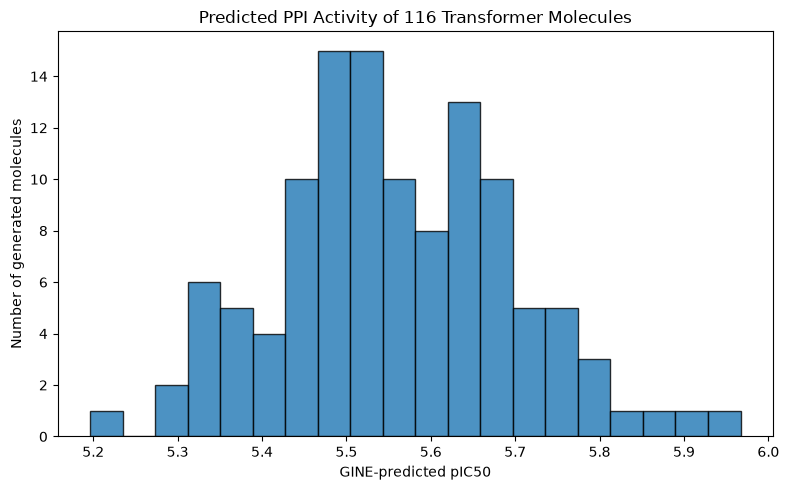

In [2]:
import matplotlib.pyplot as plt

%matplotlib inline

plt.figure(figsize=(8, 5))

plt.hist(
    df["predicted_pIC50"].dropna(),
    bins=20,
    edgecolor="black",
    alpha=0.8
)

plt.xlabel("GINE-predicted pIC50")
plt.ylabel("Number of generated molecules")
plt.title("Predicted PPI Activity of 116 Transformer Molecules")

plt.tight_layout()
plt.show()

In [3]:
top10 = (
    df.sort_values("predicted_pIC50", ascending=False)
      .head(10)
)

display(
    top10[[
        "molecule_id",
        "predicted_pIC50",
        "predicted_IC50_nM"
    ]].round(3)
)

,molecule_id,predicted_pIC50,predicted_IC50_nM
58,PPI_GEN_0059,5.967,1078.958
66,PPI_GEN_0067,5.920,1201.155
106,PPI_GEN_0107,5.855,1397.492
88,PPI_GEN_0089,5.836,1459.198
73,PPI_GEN_0074,5.808,1555.941
70,PPI_GEN_0071,5.788,1627.989
38,PPI_GEN_0039,5.779,1661.608
48,PPI_GEN_0049,5.770,1697.690
94,PPI_GEN_0095,5.760,1738.816
77,PPI_GEN_0078,5.760,1738.816
